# Embedding-Based vs TF-IDF Thematic Portfolio Construction


This project studies a simple but practical question in quantitative finance:

$
\text{Does an embedding-based thematic signal produce a better portfolio than a TF-IDF-based thematic signal when the downstream portfolio construction layer is held fixed?}
$

First, I wanted to explore how LLM-era text representations can be applied to finance without asking a language model to directly generate trades. This was discussed in class. Second, I wanted to follow the "Machine Learning for Algorithmic Trading" workflow in Jansen, which is to build a signal, translate that signal into a portfolio, and evaluate it in a backtest.

Rather than changing many parts of the pipeline at once, this notebook compares two text-to-signal methods:

1. **TF-IDF similarity** between company descriptions and an AI infrastructure theme statement  
2. **Embedding similarity** between company descriptions and AI infrastructure theme statement 

Both signals are then passed into the same convex optimizer, evaluated with the same EWMA risk model, and simulated through the same backtest. An equal-weight portfolio is included as a simple signal-free benchmark.

## Pipeline overview

$
\text{company descriptions}
\rightarrow
\text{TF-IDF / embeddings}
\rightarrow
\text{thematic score}
\rightarrow
\text{winsorize + z-score}
\rightarrow
\text{convex optimizer}
\rightarrow
\text{backtest}
\rightarrow
\text{performance evaluation}
$


In [1]:
# Core imports and notebook display settings.
import sys
from pathlib import Path
from contextlib import redirect_stdout, redirect_stderr
import io
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().resolve().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import PATH_IN, SHEET, THEME_TEXT, START_DATE, END_DATE
from src.data_ingest import load_universe, add_company_descriptions, download_prices
from src.signal_methods import add_tfidf_similarity, add_embeddings, add_embedding_similarity
from src.alpha_model import build_alpha
from src.backtest import build_all_weight_schedules, run_all_backtests
from src.metrics import compute_perf_stats

pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 160)

plt.rcParams["figure.figsize"] = (9, 4.8)
plt.rcParams["axes.grid"] = True
warnings.filterwarnings("ignore")


## Data setup

The universe starts from the S\&P 500 spreadsheet used in class. For each ticker, Yahoo Finance provides a long business summary. These summaries are then compared to a theme statement describing AI infrastructure.

The signal is cross-sectional and static: each company gets a thematic score based on its description. The portfolio is still dynamic because, at each rebalance date, the optimizer updates weights using the current covariance estimate and the previous portfolio:

$w_t = f(\alpha, \Sigma_t, w_{t-1}).$

This means the signal is slow-moving but the portfolio evolves through time.


In [2]:
# Build the dataset while suppressing long progress logs from Yahoo and embeddings.
quiet = io.StringIO()

with redirect_stdout(quiet), redirect_stderr(quiet):
    df = load_universe(PATH_IN, SHEET)
    df = add_company_descriptions(df)
    df = df[df["Company Description"].astype(str).str.strip() != ""].copy()

    # Two signal-construction methods.
    df = add_tfidf_similarity(df, THEME_TEXT)
    df["alpha_tfidf"] = build_alpha(df["tfidf_similarity"])

    df = add_embeddings(df)
    df = add_embedding_similarity(df, THEME_TEXT)
    df["alpha_embedding"] = build_alpha(df["embedding_similarity"])


df[["Ticker", "tfidf_similarity", "embedding_similarity", "alpha_tfidf", "alpha_embedding"]].head(10)


,Ticker,tfidf_similarity,embedding_similarity,alpha_tfidf,alpha_embedding
0,NVDA,0.144766,0.553535,4.360392,3.316390
1,AAPL,0.006367,0.310142,-0.274338,1.743676
2,MSFT,0.025763,0.289636,1.070106,1.370358
3,AMZN,0.008109,0.265894,-0.153547,0.938130
4,GOOGL,0.053735,0.331661,3.008905,2.135419
5,AVGO,0.083133,0.396531,4.360392,3.316390
6,GOOG,0.053735,0.332036,3.008905,2.142246
7,META,0.061484,0.358334,3.546002,2.621012
8,TSLA,0.004401,0.280193,-0.410613,1.198435
10,JPM,0.007387,0.144891,-0.203589,-1.264753


## Signal comparison

The first question is whether the two text methods produce meaningfully different signals.

The plots below are useful for that purpose:

- the score distributions show the numerical range of each method,
- the top-ranked names show which firms each method believes are most aligned with the theme,
- the scatter plot shows how much agreement exists between the two methods.

TF-IDF is driven by weighted word overlap, while embeddings are designed to capture broader semantic similarity. 


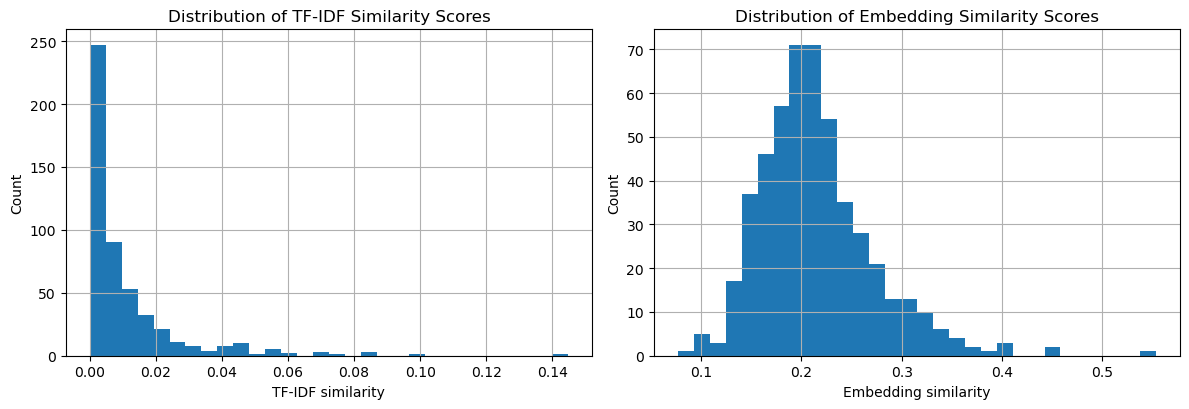

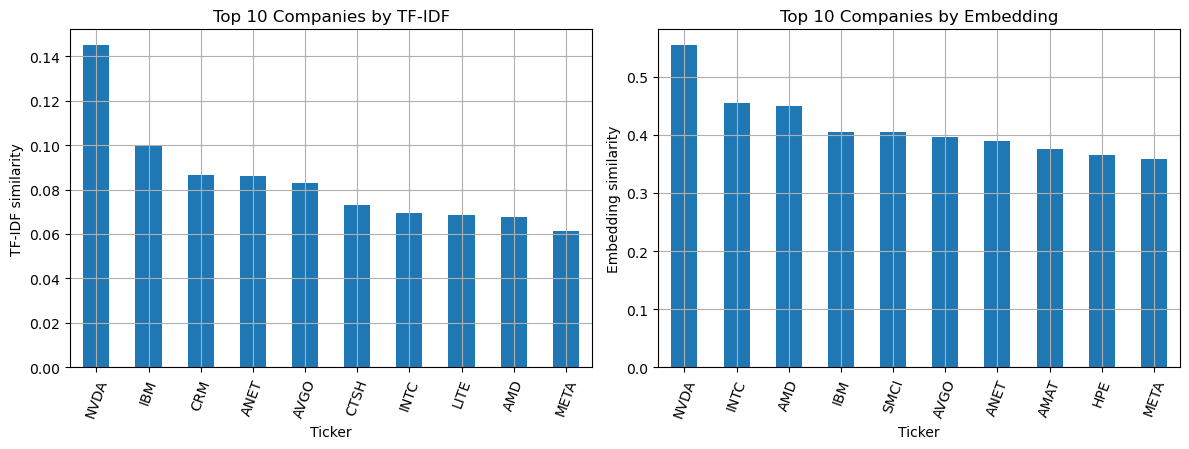

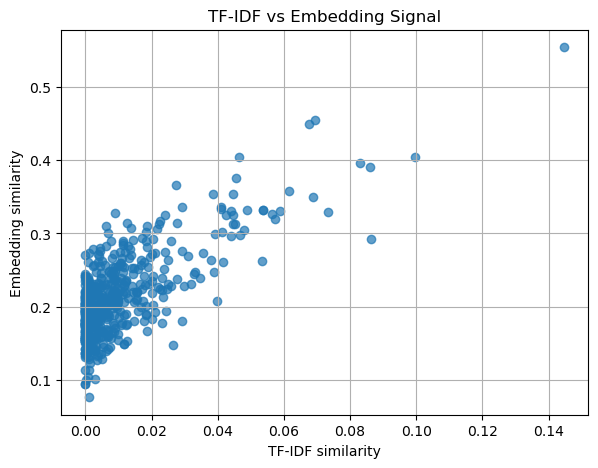

In [3]:
# Signal distributions
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

df["tfidf_similarity"].dropna().hist(bins=30, ax=axes[0])
axes[0].set_title("Distribution of TF-IDF Similarity Scores")
axes[0].set_xlabel("TF-IDF similarity")
axes[0].set_ylabel("Count")

df["embedding_similarity"].dropna().hist(bins=30, ax=axes[1])
axes[1].set_title("Distribution of Embedding Similarity Scores")
axes[1].set_xlabel("Embedding similarity")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()

# Top names under each signal
top_tfidf = (
    df[["Ticker", "tfidf_similarity"]]
    .sort_values("tfidf_similarity", ascending=False)
    .head(10)
    .set_index("Ticker")
)

top_embed = (
    df[["Ticker", "embedding_similarity"]]
    .sort_values("embedding_similarity", ascending=False)
    .head(10)
    .set_index("Ticker")
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
top_tfidf.plot(kind="bar", legend=False, ax=axes[0], title="Top 10 Companies by TF-IDF")
axes[0].set_ylabel("TF-IDF similarity")
axes[0].tick_params(axis="x", rotation=70)

top_embed.plot(kind="bar", legend=False, ax=axes[1], title="Top 10 Companies by Embedding")
axes[1].set_ylabel("Embedding similarity")
axes[1].tick_params(axis="x", rotation=70)

plt.tight_layout()
plt.show()

# Comparsion between the two signal methods
plt.figure(figsize=(6.8, 5.0))
plt.scatter(df["tfidf_similarity"], df["embedding_similarity"], alpha=0.7)
plt.xlabel("TF-IDF similarity")
plt.ylabel("Embedding similarity")
plt.title("TF-IDF vs Embedding Signal")
plt.show()


### Signal discussion

Three patterns are worth highlighting.

First, the TF-IDF distribution is highly clustered near zero. A small number of firms receive clearly higher scores because they share more of the explicit theme vocabulary.

Second, the embedding scores are more smoothly distributed. This is consistent with a semantic representation that captures broader thematic similarity rather than literal keyword overlap.

Third, the top ranked names overlap but are not identical. This is exactly the point of the project: the embedding model is not simply reproducing TF-IDF with a different scale. It appears to identify a wider AI ecosystem, while TF-IDF is more tightly tied to explicit phrase overlap.

## Portfolio construction

The portfolio step uses the same optimizer for both signals. At each rebalance date, the optimizer solves a regularized Markowitz-style problem:


$$\max_w \quad \alpha^\top w - \lambda_{\mathrm{risk}} w^\top \Sigma w - \lambda_{\mathrm{turn}} \|w-w_{t-1}\|_1$$

$$\text{subject to}$$


$$\mathbf{1}^\top w = 1, \qquad 0 \le w_i \le w_{\max}.$$

The intuition is simple:

- $\alpha^\top w$ rewards exposure to the thematic signal  
- $w^\top \Sigma w$ penalizes covariance-based portfolio risk  
- $\|w-w_{t-1}\|_1$ penalizes unnecessary trading

An equal-weight portfolio is included as a benchmark because it does not depend on text signals and therefore provides a good baseline.


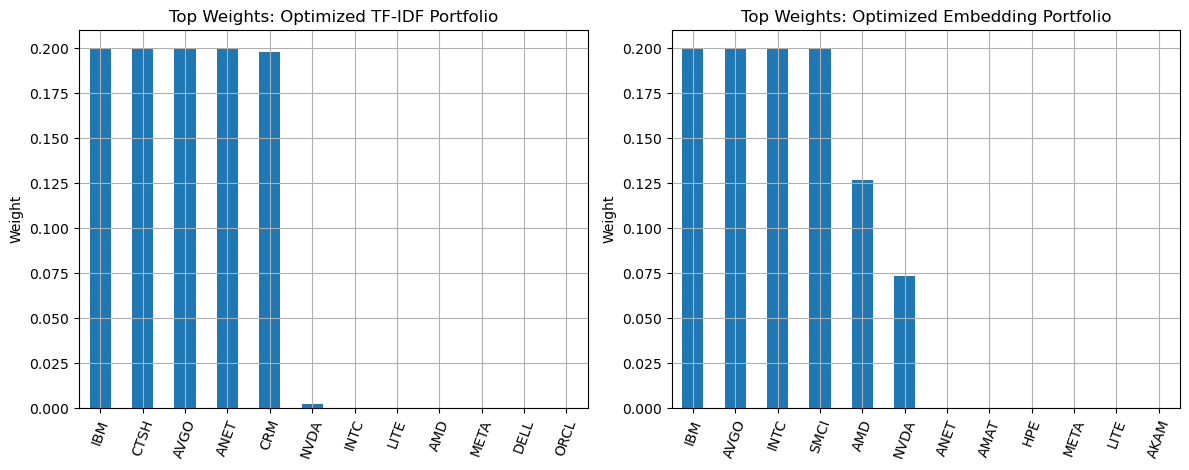

In [4]:
# Build price data, target-weight schedules, and a compact weight diagnostic.
quiet = io.StringIO()
with redirect_stdout(quiet), redirect_stderr(quiet):
    prices = download_prices(df["Ticker"].tolist(), START_DATE, END_DATE)

alpha_tfidf = df.set_index("Ticker")["alpha_tfidf"].dropna()
alpha_embedding = df.set_index("Ticker")["alpha_embedding"].dropna()
schedules = build_all_weight_schedules(prices, alpha_tfidf, alpha_embedding)

latest_tfidf = schedules["optimized_tfidf"].iloc[-1].sort_values(ascending=False).head(12)
latest_embed = schedules["optimized_embedding"].iloc[-1].sort_values(ascending=False).head(12)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
latest_tfidf.plot(kind="bar", ax=axes[0], title="Top Weights: Optimized TF-IDF Portfolio")
axes[0].set_ylabel("Weight")
axes[0].tick_params(axis="x", rotation=70)

latest_embed.plot(kind="bar", ax=axes[1], title="Top Weights: Optimized Embedding Portfolio")
axes[1].set_ylabel("Weight")
axes[1].tick_params(axis="x", rotation=70)

plt.tight_layout()
plt.show()

### Portfolio construction discussion

The bar charts show the top weights at the final rebalance date. The two portfolios tell different stories.

TF-IDF concentrates in CTSH, IBM, and CRM  whose descriptions share keyword overlap with the theme statement. NVDA is underweighted becayse its description uses technical hardware language that does not match the theme vocabulary directly, and the winsorization clips several names to the same maximum alpha score. When multiple names share identical alpha, the optimizer goes back to the covariance structure and penalizes high volatility names like NVDA. 

Embeddings produce a more intuitive result. NVDA, AVGO, and ANET receive higher weights because embeddings capture semantic meaning rather than keyword overlap, and the smoother score distribution means fewer names are clipped to the same alpha value.

Two parameters required adjustment. The initial cap of $w_{\max} = 0.05$ caused a corner solution where the top 20 names all saturated. The initial risk aversion of $\lambda_{\mathrm{risk}} = 10.0$ was too aggressive, causing the optimizer to spread weight uniformly and ignore the signal. Final parameters: $\lambda_{\mathrm{risk}} = 1.0$, $w_{\max} = 0.20$.


## Backtest results

The final step simulates all three portfolios over the full sample period:

1. equal weight  
2. optimized TF-IDF  
3. optimized embeddings

The simulation was originally implemented in Backtrader. However, with 501 feeds Backtrader had difficulty synchronizing across all data streams, causing most rebalance dates to be skipped and orders to only execute at the final date. The simulation was replaced with a simple vectorized backtest. This is ok since the signal is static and rebalancing is monthly.


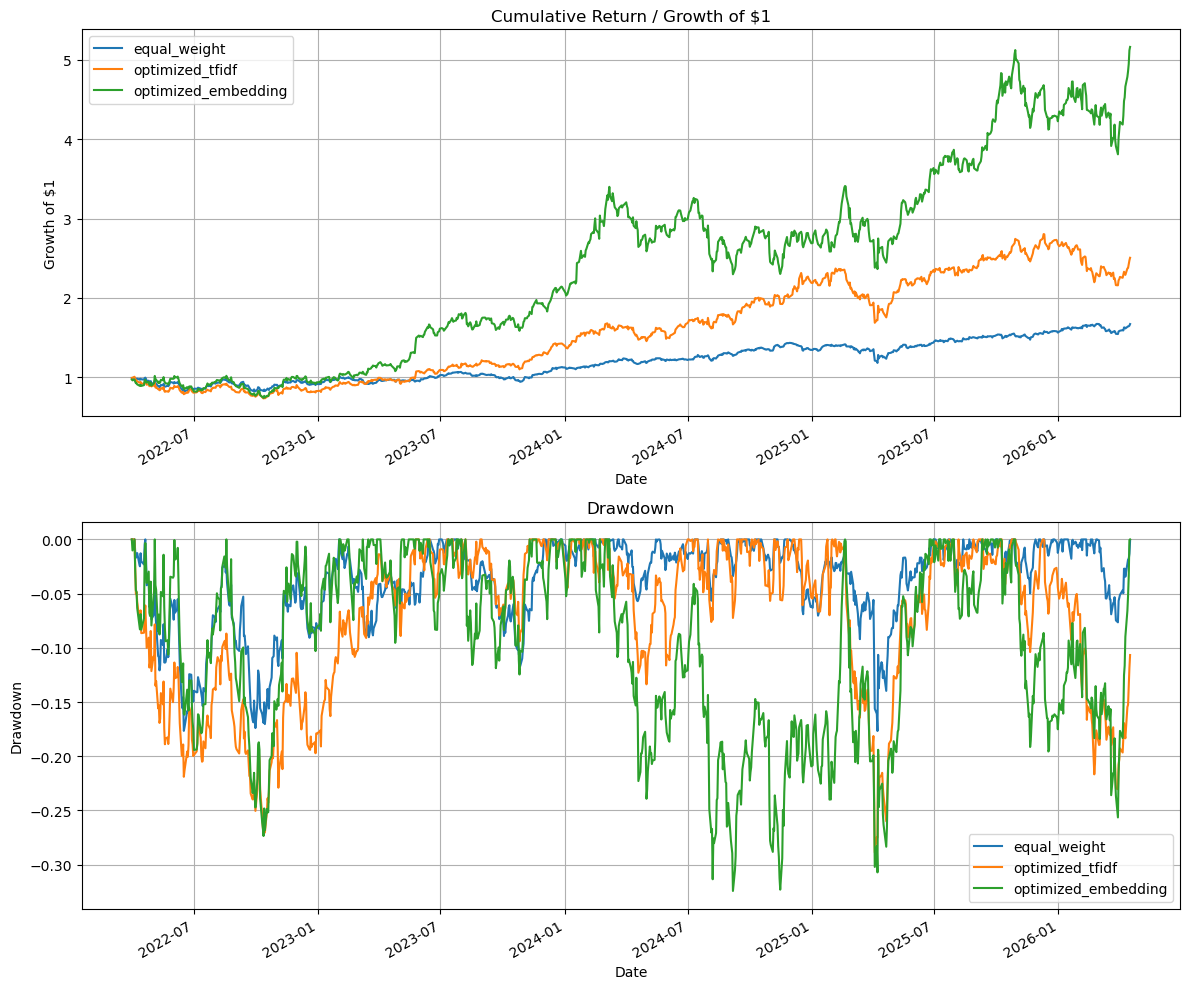

,annual_return,annual_vol,sharpe,max_drawdown
equal_weight,0.135784,0.169480,0.801176,-0.176736
optimized_tfidf,0.256130,0.260752,0.982274,-0.288696
optimized_embedding,0.503202,0.381323,1.319622,-0.324255


In [5]:
# Run all backtests and summarize results.
returns_df, values_df = run_all_backtests(prices, schedules)

summary = {}
for name in returns_df.columns:
    summary[name] = compute_perf_stats(returns_df[name].dropna())
summary_df = pd.DataFrame(summary).T

# Performance plots
cum = (1 + returns_df).cumprod()
drawdown = cum / cum.cummax() - 1

fig, axes = plt.subplots(2, 1, figsize=(12, 10))
cum.plot(ax=axes[0], title="Cumulative Return / Growth of $1")
axes[0].set_ylabel("Growth of $1")

drawdown.plot(ax=axes[1], title="Drawdown")
axes[1].set_ylabel("Drawdown")

plt.tight_layout()
plt.show()

summary_df


### Results discussion

Equal weight curve serves as the signal-free baseline. It grows modestly from $1 to ~$1.6 over the period, with an annual return of ~14% and the lowest volatility of the three. It never strays far from $1 until the 2023 AI rally, at which point it largely misses the upside due to its broad diversification across all 500 names.

Optimized TF-IDF improves on equal weight, reaching ~$2.5 and returning ~26% annually. The cumulative chart shows it tracking closely with equal weight through 2022-2023 before separating modestly. However, the concentration in CTSH, IBM, and CRM, which are names that are thematically scored highly by keyword overlap but are not the core AI infrastructure limits the upside. The max drawdown of around -29% is also larger than equal weight, reflecting the cost of concentration.

Optimized embedding is the clear winner. It grows from $1 to ~$5, delivering a 50% annual return and a Sharpe ratio of 1.32 versus 0.98 for TF-IDF and 0.81 for equal weight. The cumulative chart shows it separating sharply from mid-2023 onwards, coinciding with the NVDA-led AI infrastructure rally. This makes intuitive sense: the embedding portfolio held NVDA, AVGO, and ANET at meaningful weights, directly capturing the theme it was designed to track.

The tradeoff is higher volatility and a larger max drawdown of -32%, visible in the drawdown chart around mid-2025. This is the expected cost of a concentrated thematic bet.



## Limitations

This project has several limitations:

- Static text signal: company descriptions are slow-moving and do not capture event-level changes such as earnings calls, filings, or news.
- No supervised alpha modeling: the thematic score is not trained directly against returns.
- Simplified covariance model: EWMA is may be too simple.

These limitations are acceptable for this project because the main goal is to demonstrate a coherent pipeline that connects modern NLP-style signal construction to disciplined portfolio construction and backtesting.

## Future directions

1. Use time-varying text data such as earnings calls, filings, or news.  
2. Sector-oblivious thematic signal to separate theme exposure from obvious industry effects.  
3. Test richer risk models such as shrinkage or factor-based covariance estimators.  
4. Learn the signal or allocation policy directly in a future project, while keeping the convex optimizer as a benchmark.

The part of the project that was most interesting to me was seeing how an LLM-era text representation could be incorporated into a finance pipeline without handing the entire decision process to a language model. The final design follows a practical ML4T structure: modern text representation for feature extraction, classical optimization for allocation, and backtest for simulation.


## Conclusion
This notebook compares TF-IDF and embedding-based thematic signals inside the same portfolio construction and backtesting framework. The embedding-based approach produces a better AI-themed portfolio which suggests that richer semantic representations can improve signal construction even when the downstream allocator remains the same.

The project is less about asking an LLM to trade and more about using modern text representations to build better financial inputs.


## References

Johansson, K. K. G. F. (2025). Convex Optimization in Quantitative Finance (Doctoral dissertation, Stanford University).

Jansen, S. (2020). Machine Learning for Algorithmic Trading (2nd ed.). Packt Publishing.